# 01 — Análise Exploratória dos Dados

Este notebook apresenta a análise exploratória do conjunto de dados **EV Battery Failure Prediction Dataset**, utilizado para investigar características relacionadas à condição, degradação e falha de baterias de veículos elétricos.

A análise contempla a estrutura e os tipos das variáveis, estatísticas descritivas, valores ausentes, valores extremos, correlações e visualizações relevantes para os problemas de regressão e classificação.

Os problemas definidos para o projeto são:

- **Regressão:** previsão de `predicted_remaining_life_cycles`.
- **Classificação:** previsão de `battery_failure`.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/ev_battery_failure_dataset.csv")

print("Dimensões:", df.shape)
df.head()

Dimensões: (200000, 70)


,vehicle_id,vehicle_brand,vehicle_model,vehicle_type,manufacturing_year,battery_manufacturer,battery_chemistry,battery_capacity_kwh,drive_type,odometer_km,...,sensor_fault_count,BMS_warning_count,abnormal_voltage_events,battery_stress_index,aging_score,thermal_health_score,charging_quality_score,driving_stress_score,predicted_remaining_life_cycles,battery_failure
0,EV100000,Nissan,Leaf,SUV,2019.0,CATL,LMO,82.54,RWD,98163.0,...,2.0,3.0,0.0,0.0,53.5,66.0,65.2,0.0,401.0,0
1,EV100001,Audi,e-tron,Sedan,2018.0,Samsung SDI,NaN,64.17,AWD,113600.0,...,0.0,3.0,0.0,51.0,38.8,67.8,46.3,40.9,1094.0,0
2,EV100002,Toyota,bZ4X,Van,2018.0,Guoxuan,NMC,90.92,RWD,242253.0,...,4.0,1.0,0.0,36.2,66.1,48.6,0.0,6.5,645.0,0
3,EV100003,Volkswagen,ID.3,Hatchback,2022.0,CATL,NMC,47.35,AWD,83700.0,...,0.0,3.0,1.0,23.4,32.5,58.2,NaN,NaN,867.0,0
4,EV100004,Tesla,Model X,Crossover,2015.0,BYD Battery,NMC,68.04,FWD,88784.0,...,3.0,2.0,1.0,51.2,45.4,51.0,NaN,100.0,1090.0,0


## Carregamento e visão inicial dos dados

O conjunto de dados possui **200.000 registros e 70 variáveis**, incluindo informações relacionadas aos veículos, características das baterias, padrões de carregamento e condução, condições ambientais, manutenção e indicadores de saúde e degradação.

A inspeção inicial permite verificar a estrutura do conjunto e confirmar que os dados foram carregados corretamente antes das demais etapas da análise exploratória.

In [ ]:
print(f"Quantidade de linhas: {df.shape[0]:,}")
print(f"Quantidade de colunas: {df.shape[1]}")

Quantidade de linhas: 200,000
Quantidade de colunas: 70


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 70 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   vehicle_id                       200000 non-null  object 
 1   vehicle_brand                    193564 non-null  object 
 2   vehicle_model                    191796 non-null  object 
 3   vehicle_type                     193568 non-null  object 
 4   manufacturing_year               190171 non-null  float64
 5   battery_manufacturer             193812 non-null  object 
 6   battery_chemistry                192786 non-null  object 
 7   battery_capacity_kwh             193097 non-null  float64
 8   drive_type                       192732 non-null  object 
 9   odometer_km                      191334 non-null  float64
 10  vehicle_age_years                192317 non-null  float64
 11  fleet_or_private                 191050 non-null  object 
 12  ba

## Estatísticas descritivas

As estatísticas descritivas permitem observar a distribuição das variáveis numéricas, incluindo medidas de tendência central, dispersão e valores mínimos e máximos. Essa etapa auxilia na identificação inicial de diferenças de escala, possíveis assimetrias e valores extremos.

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
manufacturing_year,190171.0,2019.501333,2.873497,2015.00000,2017.000000,2020.00000,2022.00000,2024.00000
battery_capacity_kwh,193097.0,76.236405,21.302330,25.00000,60.980000,75.35000,89.99000,149.01000
odometer_km,191334.0,102822.193327,87965.819977,500.00000,36128.000000,78919.00000,146010.75000,450000.00000
vehicle_age_years,192317.0,6.495245,2.878180,1.37000,4.000000,6.34000,9.00000,11.55000
cycle_count,192348.0,296.383934,282.614453,1.00000,95.000000,218.00000,412.00000,3369.00000
battery_health_percent,191018.0,87.381787,12.540742,21.42000,80.990000,91.12000,97.43000,99.80000
state_of_charge,190364.0,54.847079,21.450372,2.00000,40.070000,54.94000,69.78000,100.00000
depth_of_discharge,191687.0,38.290397,12.754524,5.00000,29.600000,38.28000,46.91000,92.03000
state_of_health,190435.0,87.297020,12.527256,21.80000,80.910000,91.05000,97.33000,100.00000
cell_voltage_avg,190602.0,3.288515,0.246766,2.04850,3.106025,3.35580,3.46390,3.85300


## Variáveis categóricas

As variáveis categóricas foram identificadas e analisadas por meio da frequência de suas categorias. Essa análise permite compreender a composição do conjunto de dados e verificar possíveis desequilíbrios entre categorias.

In [ ]:
# Variáveis categóricas
categorical_cols = df.select_dtypes(include='object').columns

print("Quantidade de variáveis categóricas:", len(categorical_cols))
print(categorical_cols.tolist())

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False).head(15))

Quantidade de variáveis categóricas: 10
['vehicle_id', 'vehicle_brand', 'vehicle_model', 'vehicle_type', 'battery_manufacturer', 'battery_chemistry', 'drive_type', 'fleet_or_private', 'battery_serial', 'terrain_type']

--- vehicle_id ---
vehicle_id
EV299983    1
EV299982    1
EV299981    1
EV299980    1
EV299979    1
EV299978    1
EV299977    1
EV299976    1
EV299975    1
EV299974    1
EV299973    1
EV299972    1
EV299971    1
EV299970    1
EV299969    1
Name: count, dtype: int64

--- vehicle_brand ---
vehicle_brand
Tesla         21840
BYD           20187
Volkswagen    14629
Hyundai       12940
GM            11087
Ford          10924
Kia           10780
Mercedes       9193
Nissan         9108
BMW            9063
Toyota         9039
Tata           7372
Audi           7287
Volvo          7276
Renault        7268
Name: count, dtype: int64

--- vehicle_model ---
vehicle_model
NaN                8204
Model X            5527
F-150 Lightning    5486
Model S            5380
Model 3            

## Valores ausentes

Foram identificados valores ausentes em 67 variáveis do conjunto de dados. Entretanto, os percentuais de ausência são relativamente baixos, variando aproximadamente entre 3% e 5%.

A maior proporção foi observada em `fast_charge_ratio`, com 9.879 valores ausentes, correspondendo a aproximadamente 4,94% dos registros. Não foram identificadas variáveis com ausência excessiva que justificasse sua exclusão.

Na etapa de pré-processamento, esses valores serão tratados de acordo com o tipo das variáveis.

In [ ]:
# Análise de valores ausentes
missing = pd.DataFrame({
    'quantidade': df.isnull().sum(),
    'percentual': (df.isnull().sum() / len(df)) * 100
})

missing = missing[missing['quantidade'] > 0]
missing = missing.sort_values('percentual', ascending=False)

missing

,quantidade,percentual
fast_charge_ratio,9879,4.9395
average_speed,9849,4.9245
manufacturing_year,9829,4.9145
home_charging_ratio,9805,4.9025
sensor_fault_count,9674,4.8370
...,...,...
battery_manufacturer,6188,3.0940
pack_voltage,6175,3.0875
average_charging_time,6149,3.0745
remaining_capacity,6148,3.0740


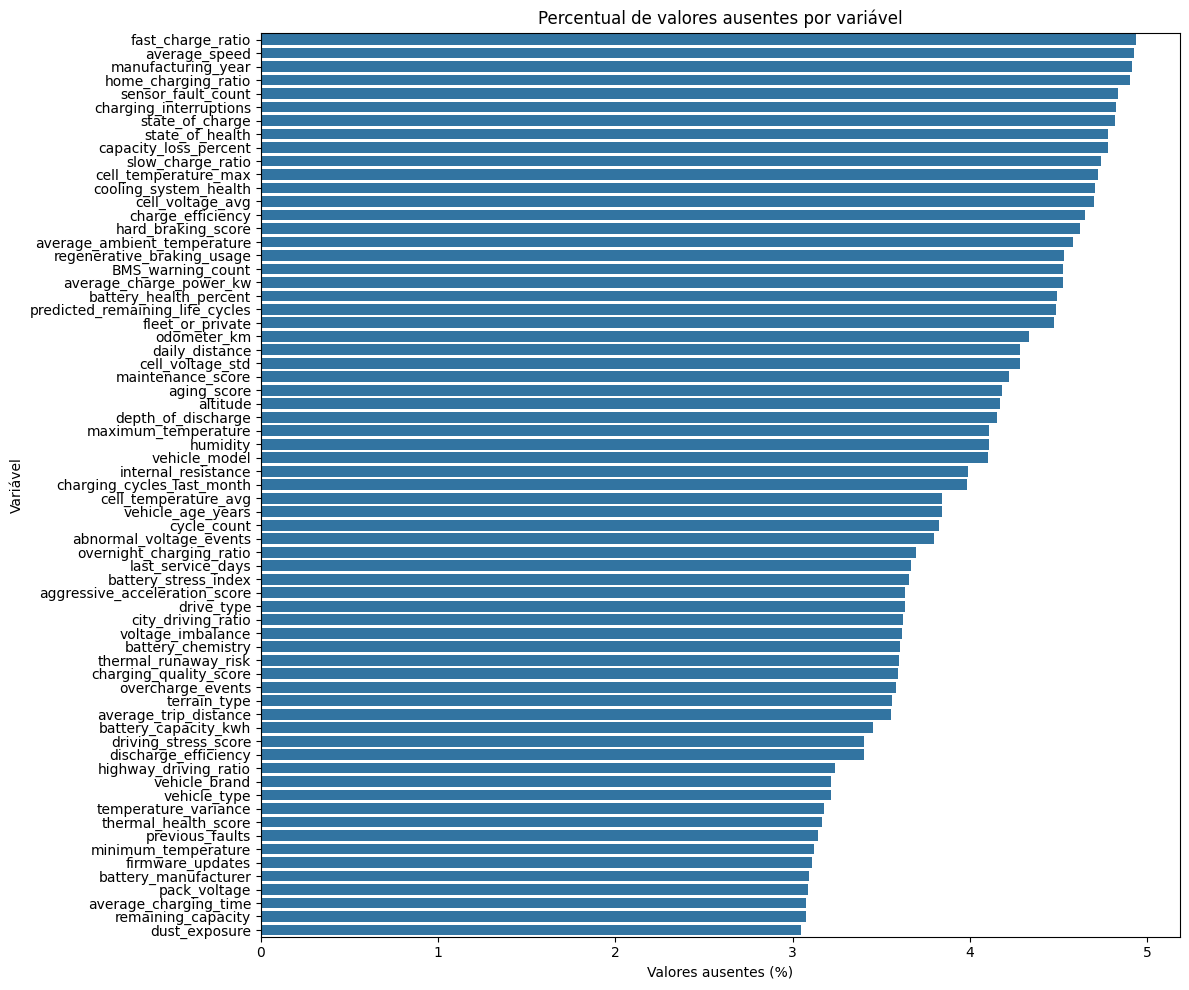

In [ ]:
# Visualização dos valores ausentes
plt.figure(figsize=(12, 10))

sns.barplot(
    data=missing.reset_index(),
    x='percentual',
    y='index'
)

plt.xlabel('Valores ausentes (%)')
plt.ylabel('Variável')
plt.title('Percentual de valores ausentes por variável')

plt.tight_layout()
plt.show()

## Análise de valores extremos

Os valores extremos das variáveis numéricas foram identificados utilizando o método do intervalo interquartil (IQR). O método considera como potenciais outliers os valores localizados abaixo de 1,5 vezes o IQR em relação ao primeiro quartil ou acima de 1,5 vezes o IQR em relação ao terceiro quartil.

In [ ]:
# Identificação de outliers pelo método IQR
numeric_cols = df.select_dtypes(include=np.number).columns

outliers = {}

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    quantidade = (
        (df[col] < limite_inferior) |
        (df[col] > limite_superior)
    ).sum()

    outliers[col] = quantidade

outliers_df = pd.DataFrame.from_dict(
    outliers,
    orient='index',
    columns=['quantidade_outliers']
)

outliers_df['percentual'] = (
    outliers_df['quantidade_outliers'] / len(df) * 100
)

outliers_df = outliers_df.sort_values(
    'quantidade_outliers',
    ascending=False
)

outliers_df.head(15)

,quantidade_outliers,percentual
battery_failure,19921,9.9605
average_charging_time,12983,6.4915
cycle_count,8547,4.2735
last_service_days,8412,4.2060
pack_voltage,7064,3.5320
odometer_km,6639,3.3195
average_trip_distance,5794,2.8970
overcharge_events,5640,2.8200
capacity_loss_percent,5461,2.7305
battery_health_percent,5455,2.7275


A aplicação do método IQR identificou valores extremos em diversas variáveis. Entre as maiores proporções estão `average_charging_time` (6,49%), `cycle_count` (4,27%), `last_service_days` (4,21%), `pack_voltage` (3,53%) e `odometer_km` (3,32%).

Entretanto, a identificação pelo IQR não implica necessariamente que esses registros sejam erros, pois valores extremos podem representar condições válidas de operação das baterias e dos veículos. Por esse motivo, optou-se por não realizar a remoção indiscriminada desses registros.

A variável `battery_failure` também foi sinalizada pelo método, porém esse resultado foi desconsiderado, pois se trata de uma variável binária e a interpretação de outliers pelo IQR não é adequada nesse caso.

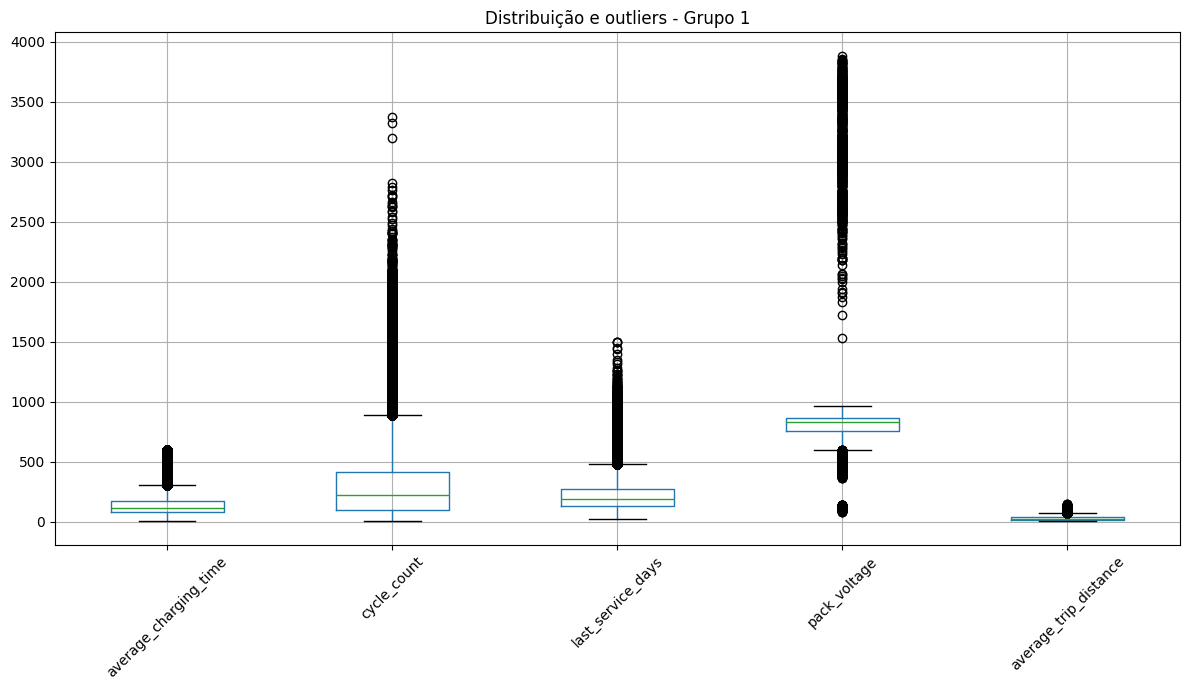

In [ ]:
cols_boxplot_1 = [
    'average_charging_time',
    'cycle_count',
    'last_service_days',
    'pack_voltage',
    'average_trip_distance'
]

plt.figure(figsize=(12, 7))
df[cols_boxplot_1].boxplot()
plt.title('Distribuição e outliers - Grupo 1')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

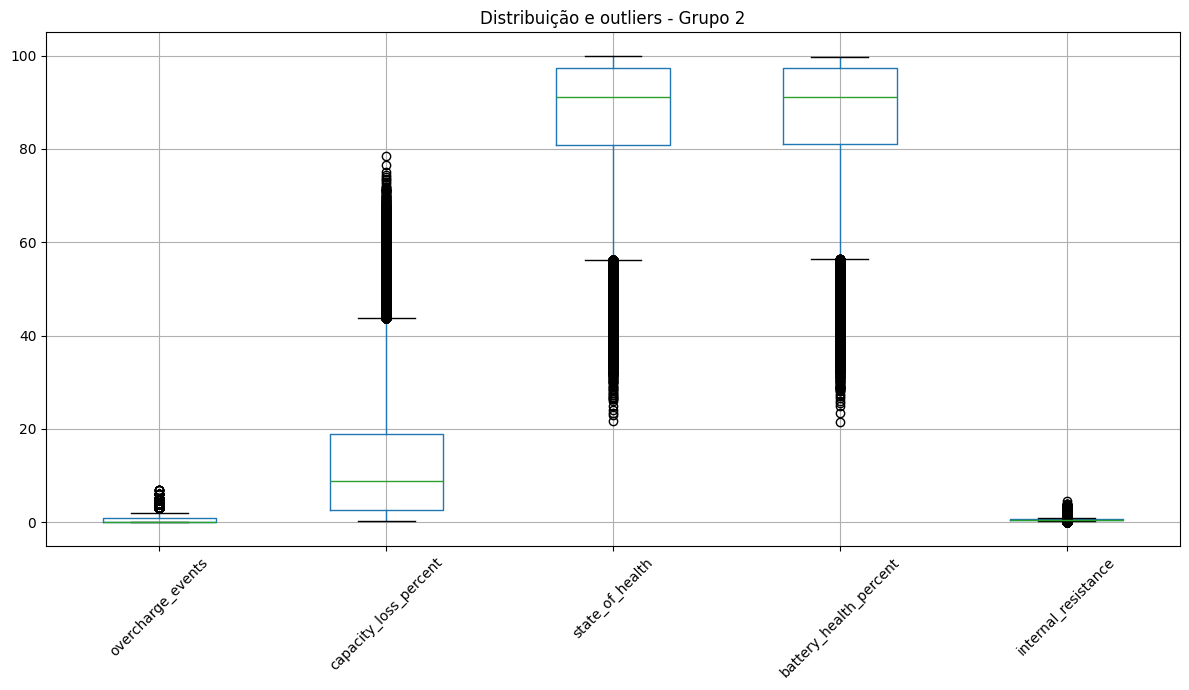

In [ ]:
cols_boxplot_2 = [
    'overcharge_events',
    'capacity_loss_percent',
    'state_of_health',
    'battery_health_percent',
    'internal_resistance'
]

plt.figure(figsize=(12, 7))
df[cols_boxplot_2].boxplot()
plt.title('Distribuição e outliers - Grupo 2')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Correlação e multicolinearidade

A matriz de correlação foi utilizada para investigar relações lineares entre as variáveis numéricas e identificar possíveis casos de multicolinearidade.

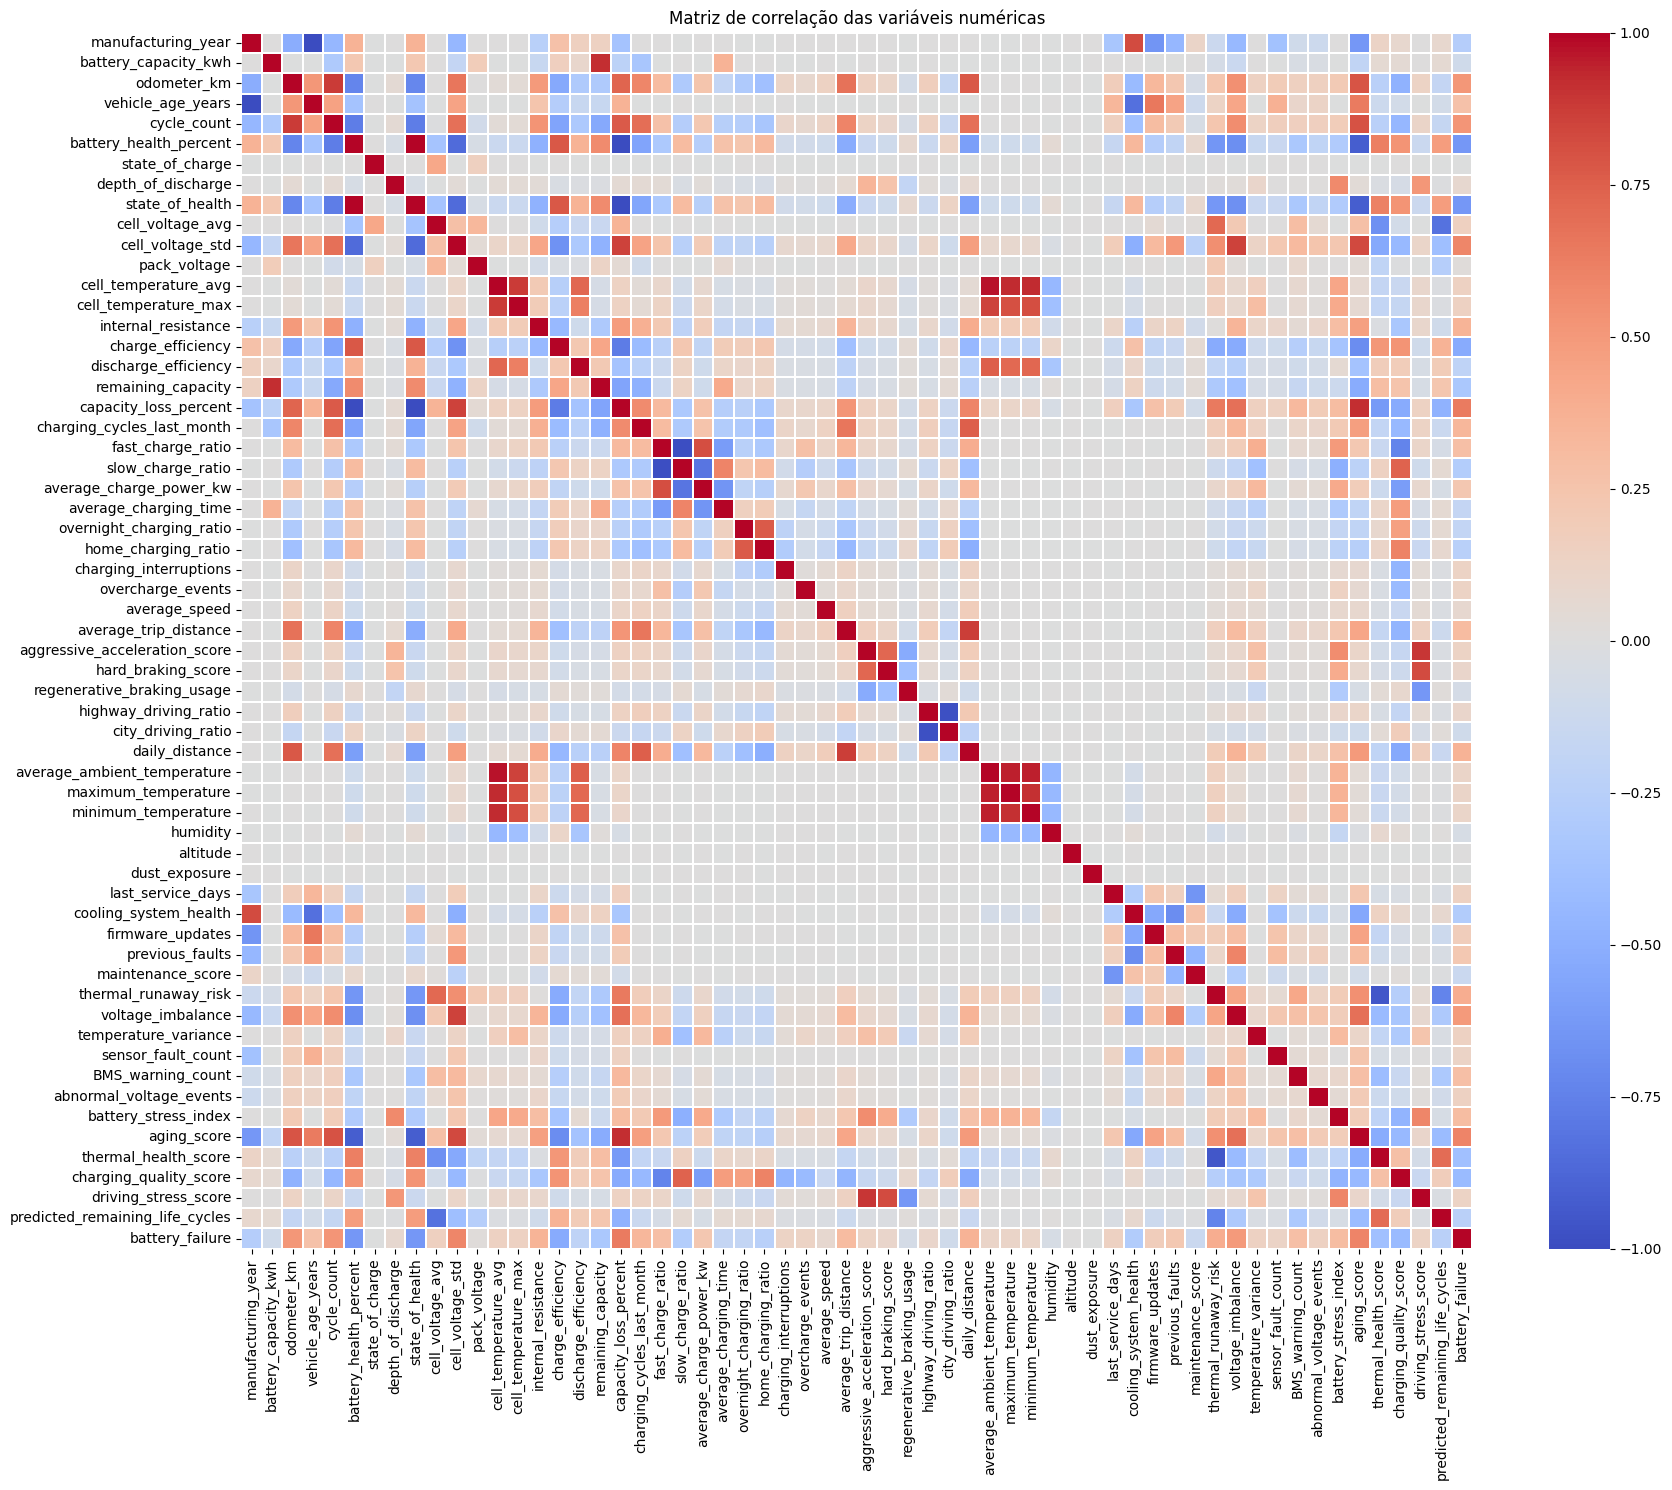

In [ ]:
# Matriz de correlação das variáveis numéricas
corr = df.select_dtypes(include=np.number).corr()

plt.figure(figsize=(18, 15))

sns.heatmap(
    corr,
    cmap='coolwarm',
    center=0,
    linewidths=0.1
)

plt.title('Matriz de correlação das variáveis numéricas')
plt.tight_layout()
plt.show()

In [ ]:
# Pares de variáveis com maiores correlações absolutas

corr_pairs = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
).stack().reset_index()

corr_pairs.columns = ['variavel_1', 'variavel_2', 'correlacao']

corr_pairs['correlacao_absoluta'] = corr_pairs['correlacao'].abs()

corr_pairs = corr_pairs.sort_values(
    'correlacao_absoluta',
    ascending=False
)

corr_pairs.head(20)

,variavel_1,variavel_2,correlacao,correlacao_absoluta
297,battery_health_percent,capacity_loss_percent,-1.000000,1.000000
2,manufacturing_year,vehicle_age_years,-0.998636,0.998636
453,state_of_health,capacity_loss_percent,-0.994379,0.994379
287,battery_health_percent,state_of_health,0.994374,0.994374
990,fast_charge_ratio,slow_charge_ratio,-0.986959,0.986959
1419,highway_driving_ratio,city_driving_ratio,-0.981943,0.981943
665,cell_temperature_avg,average_ambient_temperature,0.972741,0.972741
1495,average_ambient_temperature,minimum_temperature,0.952658,0.952658
1494,average_ambient_temperature,maximum_temperature,0.952299,0.952299
1699,thermal_runaway_risk,thermal_health_score,-0.951612,0.951612


A análise revelou correlações muito fortes entre algumas variáveis. Destacam-se `battery_health_percent` e `capacity_loss_percent` (r = -1,000), `manufacturing_year` e `vehicle_age_years` (r = -0,999), `state_of_health` e `capacity_loss_percent` (r = -0,994), `fast_charge_ratio` e `slow_charge_ratio` (r = -0,987) e `highway_driving_ratio` e `city_driving_ratio` (r = -0,982).

Esses resultados indicam presença de multicolinearidade. Em modelos sensíveis a esse problema, especialmente modelos lineares, pode ser adequado selecionar apenas uma característica entre pares altamente correlacionados ou utilizar técnicas de regularização.

In [ ]:
from scipy.stats import chi2_contingency

categorical_features = [
    'vehicle_brand',
    'vehicle_model',
    'vehicle_type',
    'battery_manufacturer',
    'battery_chemistry',
    'drive_type',
    'fleet_or_private',
    'terrain_type'
]

chi_results = []

for feature in categorical_features:
    tabela = pd.crosstab(
        df[feature],
        df['battery_failure']
    )

    qui2, p_valor, graus_liberdade, esperados = chi2_contingency(tabela)

    chi_results.append({
        'variavel': feature,
        'qui2': qui2,
        'graus_liberdade': graus_liberdade,
        'p_valor': p_valor
    })

chi_df = pd.DataFrame(chi_results)

chi_df.sort_values('p_valor')

,variavel,qui2,graus_liberdade,p_valor
6,fleet_or_private,6964.499048,1,0.000000e+00
4,battery_chemistry,2425.584926,4,0.000000e+00
0,vehicle_brand,1032.926575,19,4.946061e-207
1,vehicle_model,1053.813952,54,2.231534e-185
2,vehicle_type,528.379247,5,5.964928e-112
3,battery_manufacturer,10.584249,8,2.263866e-01
5,drive_type,2.047902,2,3.591730e-01
7,terrain_type,2.213452,4,6.965674e-01


## Análise das variáveis-alvo

Para o problema de regressão, foi selecionada a variável `predicted_remaining_life_cycles`, que representa a vida útil restante prevista da bateria em número de ciclos.

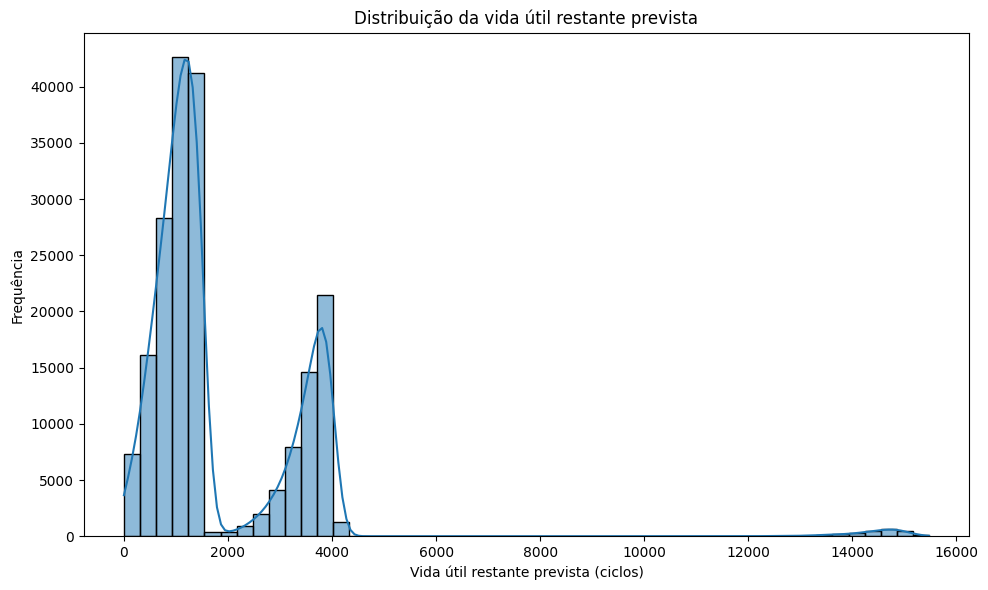

In [ ]:
# Distribuição do alvo de regressão

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='predicted_remaining_life_cycles',
    bins=50,
    kde=True
)

plt.xlabel('Vida útil restante prevista (ciclos)')
plt.ylabel('Frequência')
plt.title('Distribuição da vida útil restante prevista')

plt.tight_layout()
plt.show()

A variável apresenta ampla variabilidade e uma distribuição não uniforme, com diferentes concentrações de observações. Essa característica indica que a previsão da vida útil restante pode envolver relações complexas e potencialmente não lineares com as demais variáveis.

Para o problema de classificação, foi selecionada a variável `battery_failure`, que representa a ausência (0) ou ocorrência (1) de falha da bateria.

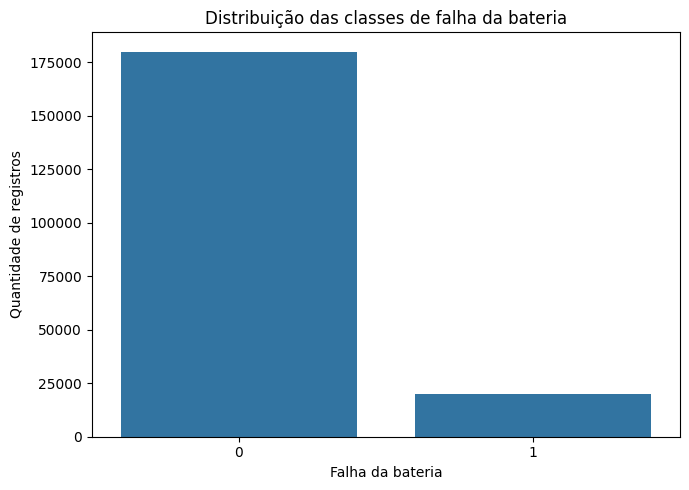

battery_failure
0    180079
1     19921
Name: count, dtype: int64

battery_failure
0    90.0395
1     9.9605
Name: proportion, dtype: float64


In [ ]:
# Distribuição do alvo de classificação

failure_counts = df['battery_failure'].value_counts().sort_index()

plt.figure(figsize=(7, 5))

sns.barplot(
    x=failure_counts.index,
    y=failure_counts.values
)

plt.xlabel('Falha da bateria')
plt.ylabel('Quantidade de registros')
plt.title('Distribuição das classes de falha da bateria')

plt.tight_layout()
plt.show()

print(df['battery_failure'].value_counts())
print()
print(df['battery_failure'].value_counts(normalize=True) * 100)

A variável apresenta desbalanceamento entre as classes. Aproximadamente **90,04%** dos registros pertencem à classe sem falha, enquanto **9,96%** pertencem à classe com falha.

Esse desequilíbrio deverá ser considerado posteriormente na escolha das métricas de avaliação e na construção dos modelos de classificação.

## Relação inicial entre degradação e falha

Para investigar uma possível relação entre a degradação da bateria e a ocorrência de falha, foi analisada a distribuição de `capacity_loss_percent` entre as duas classes de `battery_failure`.

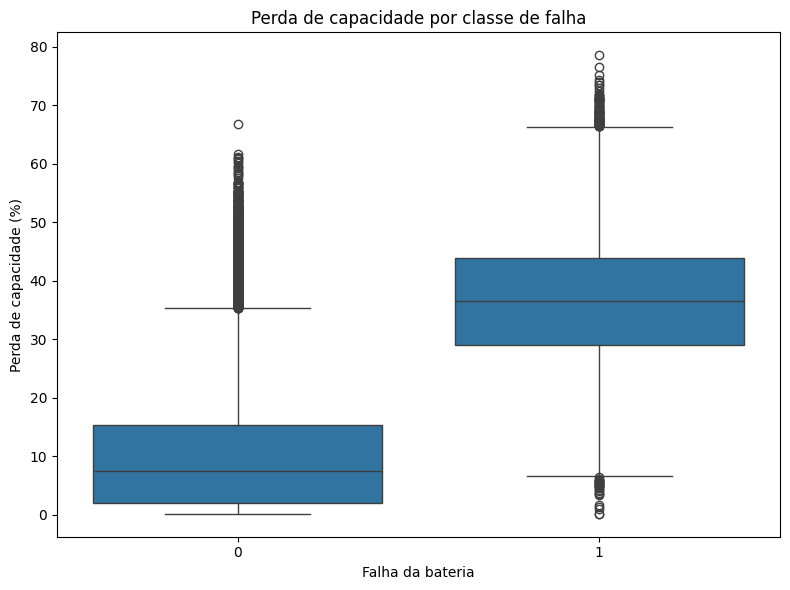

In [ ]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x='battery_failure',
    y='capacity_loss_percent'
)

plt.xlabel('Falha da bateria')
plt.ylabel('Perda de capacidade (%)')
plt.title('Perda de capacidade por classe de falha')

plt.tight_layout()
plt.show()

In [ ]:
df.groupby('battery_failure')['capacity_loss_percent'].describe()

,count,mean,std,min,25%,50%,75%,max
battery_failure,,,,,,,,
0,171440.0,9.955971,9.471448,0.2,1.99,7.46,15.37,66.89
1,19001.0,36.690577,11.188185,0.2,29.04,36.52,43.98,78.58


A diferença entre as classes é expressiva. A mediana de `capacity_loss_percent` é de aproximadamente **7,46%** nos registros sem falha e **36,52%** nos registros com falha.

Esse resultado sugere que a perda de capacidade pode constituir uma característica relevante para a identificação de falhas, hipótese que será analisada com maior profundidade no notebook específico de classificação.

## Conclusões da análise exploratória

O conjunto de dados possui 200.000 registros e 70 variáveis, abrangendo características do veículo, bateria, carregamento, condução, ambiente, manutenção e indicadores de saúde da bateria.

Foram identificados valores ausentes em 67 variáveis, porém em proporções relativamente baixas, aproximadamente entre 3% e 5%. Também foram encontrados valores extremos em diversas características, mas estes não foram removidos nesta etapa por poderem representar condições válidas de operação.

A análise de correlação evidenciou forte multicolinearidade entre algumas variáveis, aspecto que deverá ser considerado durante a seleção de características.

Para regressão, `predicted_remaining_life_cycles` apresenta ampla variabilidade e distribuição não uniforme. Para classificação, `battery_failure` apresenta forte desbalanceamento, com aproximadamente 90% dos registros pertencentes à classe sem falha.

A análise exploratória também revelou diferenças relevantes em características relacionadas à degradação da bateria, fornecendo evidências para as etapas posteriores de pré-processamento e análise específica dos problemas de regressão e classificação.